# German reunification

GDP per capita, 1960–2003; first comparison post-period 1990. Outcome: GDP per capita in the source's US-dollar units.

Abadie, Diamond and Hainmueller (2015), [AJPS](https://doi.org/10.1111/ajps.12116). The historical two-stage predictor-weight specification is checked against the pysyncon reference ATT −1555.13468, with its predeclared 2.5% numerical tolerance. That reference includes 1990 in predictor means and the training validation window. We retain this historical convention explicitly; all common-comparison models below fit only years **strictly before 1990**.

Run from a checkout installed using `requirements-replication.txt` and `pip install -e .`. This notebook downloads immutable public data using **requests**; an internet connection is required. See [the replication guide](../docs/replication.md) for provenance and scope.

In [1]:
%matplotlib inline
import hashlib
from io import BytesIO
from importlib.metadata import version

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from pysynth import (SyntheticControl, SCUL, IndividualSC, SyntheticDID,
                     DifferenceInDifferences, PySyncon, SCM, compare)
from pysynth.datasets import DATASETS
from pysynth.replication import replicate, check_replication

pd.Series({p: version(p) for p in ['pysynth-control', 'numpy', 'scipy', 'pandas', 'pysyncon', 'SyntheticControlMethods']}, name='version')

pysynth-control             0.1.0
numpy                       2.0.2
scipy                      1.13.1
pandas                      2.3.3
pysyncon                    1.7.0
SyntheticControlMethods    1.1.17
Name: version, dtype: object

## Download and verify the academic data

The URL names an immutable upstream commit. SHA256 verification fails visibly if the bytes differ. No manual download or bundled dataset is required.

In [2]:
name = 'germany'
spec = DATASETS[name]
response = requests.get(spec.url, timeout=30)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == spec.sha256
data = pd.read_csv(BytesIO(response.content), sep=spec.separator)
panel = spec.panel(data)
print(spec.citation)
print(spec.url)
print(f'{panel.n_control} donors; {panel.n_pre} pre-periods; {panel.n_post} post-periods')
data.head()

Abadie, Diamond & Hainmueller (2015), doi:10.1111/ajps.12116
https://raw.githubusercontent.com/sdfordham/pysyncon/b77dc20e29b012ab03ca1d4caeef7b41861e86f5/data/germany.csv
16 donors; 30 pre-periods; 14 post-periods


,code,country,year,gdp,infrate,trade,schooling,invest60,invest70,invest80,industry
0,1,USA,1960,2879,NaN,9.693181,43.799999,NaN,NaN,NaN,NaN
1,1,USA,1961,2929,1.075182,9.444655,NaN,NaN,NaN,NaN,NaN
2,1,USA,1962,3103,1.116071,9.429324,NaN,NaN,NaN,NaN,NaN
3,1,USA,1963,3227,1.214128,9.470706,NaN,NaN,NaN,NaN,NaN
4,1,USA,1964,3420,1.308615,9.725879,NaN,NaN,NaN,NaN,NaN


## Reference specification and numerical check

This cell uses the historical specification described above. Its assertion is separate from the new-method comparison. See `pysynth.replication.replicate` for the full predictor windows and optimization settings.

source                pysyncon reference ATT, 1990–2003
estimate                                   -1555.134678
reference                                  -1555.134678
absolute_tolerance                            38.878367
Name: Replication check, dtype: object

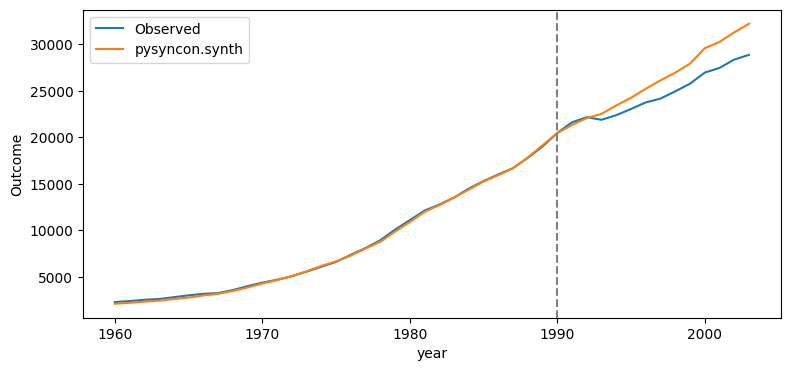

In [3]:
reference = replicate(name, data)
report = check_replication(name, reference)
display(pd.Series(report, name='Replication check'))
reference.plot()
plt.show()

## Compare all applicable methods

All rows use the same outcome panel, donor eligibility and intervention date. Native SCM assigns equal importance to outcome periods; the pysyncon SCM adapter standardizes predictor rows. Penalized and robust SCM use explicit illustrative tuning values below. The SyntheticControlMethods rows use at most ten evenly spaced pre-outcome lag predictors plus its outcome mean; this keeps the nested optimization practical for quarterly panels. SCUL selects its penalty by rolling validation entirely within the pre-period, using a shared pretreatment penalty grid.

IndividualSC is evaluated as a single-case, screened-donor application of the costofcare workflow, with at most ten donors. This is not a reproduction of the Vagni–Breen survey study. SDID uses donor post-period outcomes to learn time weights, and robust SCM denoises donors over the full panel; neither uses treated post outcomes to estimate weights. The newer methods' rows are **new applications**, not estimates published in their development papers.

Upstream convergence warnings remain visible. No method is silently dropped if fitting fails.

In [4]:
models = {
    'Outcome SCM': SyntheticControl(),
    'SCUL': SCUL(initial_window=max(3, panel.n_pre // 2), horizon=1),
    'Individual SC (nearest 10)': IndividualSC(n_neighbors=10),
    'Synthetic DID': SyntheticDID(),
    'DID': DifferenceInDifferences(),
    'pysyncon SCM': PySyncon('synth'),
    'Augmented SCM': PySyncon('augsynth'),
    'Penalized SCM (0.01)': PySyncon('pensynth', options={'lambda_': 0.01}),
    'Robust SCM (rank 3, ridge 0.1)': PySyncon('robust', options={'lambda_': 0.1, 'sv_count': 3}),
    'SyntheticControlMethods SCM': SCM('synth', n_lags=10),
    'Differenced SCM': SCM('diffsynth', n_lags=10),
}
results = {label: model.fit(panel) for label, model in models.items()}
comparison = compare(results)
comparison.round(4)

/tmp/ipykernel_3575488/721986126.py:14: RuntimeWarning: SDID reached max_iter before the objective-decrease stopping rule
  results = {label: model.fit(panel) for label, model in models.items()}


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           11     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  1.54077D+05    |proj g|=  9.09091D-01

At iterate    3    f=  1.38652D+05    |proj g|=  6.35704D-01



At iterate    6    f=  1.35919D+05    |proj g|=  8.89329D-01

At iterate    9    f=  1.29234D+05    |proj g|=  1.00000D+00
  ys=-1.982E+04  -gs= 8.662E+02 BFGS update SKIPPED



At iterate   12    f=  1.28178D+05    |proj g|=  9.83456D-01
  Positive dir derivative in projection 
  Using the backtracking step 



At iterate   15    f=  1.26290D+05    |proj g|=  9.56183D-01

At iterate   18    f=  1.23355D+05    |proj g|=  8.81167D-01



At iterate   21    f=  1.19652D+05    |proj g|=  8.14457D-01


... (14 outputs left out)


 Bad direction in the line search;
   refresh the lbfgs memory and restart the iteration.



           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
   11     42    193     78     2    11   9.525D-01   5.544D+04
  F =   55441.355675272694     

ABNORMAL_TERMINATION_IN_LNSRCH                              



 Line search cannot locate an adequate point after MAXLS
  function and gradient evaluations.
  Previous x, f and g restored.
 Possible causes: 1 error in function or gradient evaluation;
                  2 rounding error dominate computation.


,att,pre_rmse,donors_used,weight_sum
model,,,,
Outcome SCM,-1304.6958,60.8666,7,1.0000
SCUL,-1653.0600,45.0692,5,1.0680
Individual SC (nearest 10),-1821.2453,69.3815,6,1.0000
Synthetic DID,-1471.3949,100.5897,13,1.0000
DID,603.9836,713.2782,16,1.0000
pysyncon SCM,-1843.4961,74.3020,9,1.0000
Augmented SCM,-1495.0864,33.2871,16,1.0000
Penalized SCM (0.01),-1738.6838,76.5068,5,1.0000
"Robust SCM (rank 3, ridge 0.1)",-2208.8650,93.1927,16,1.1384


## Estimated effect paths

Differences across estimates reflect different restrictions, extrapolation, regularization and level adjustments. Pre-period RMSE measures fit; it does not validate the identifying assumptions or rank causal credibility.

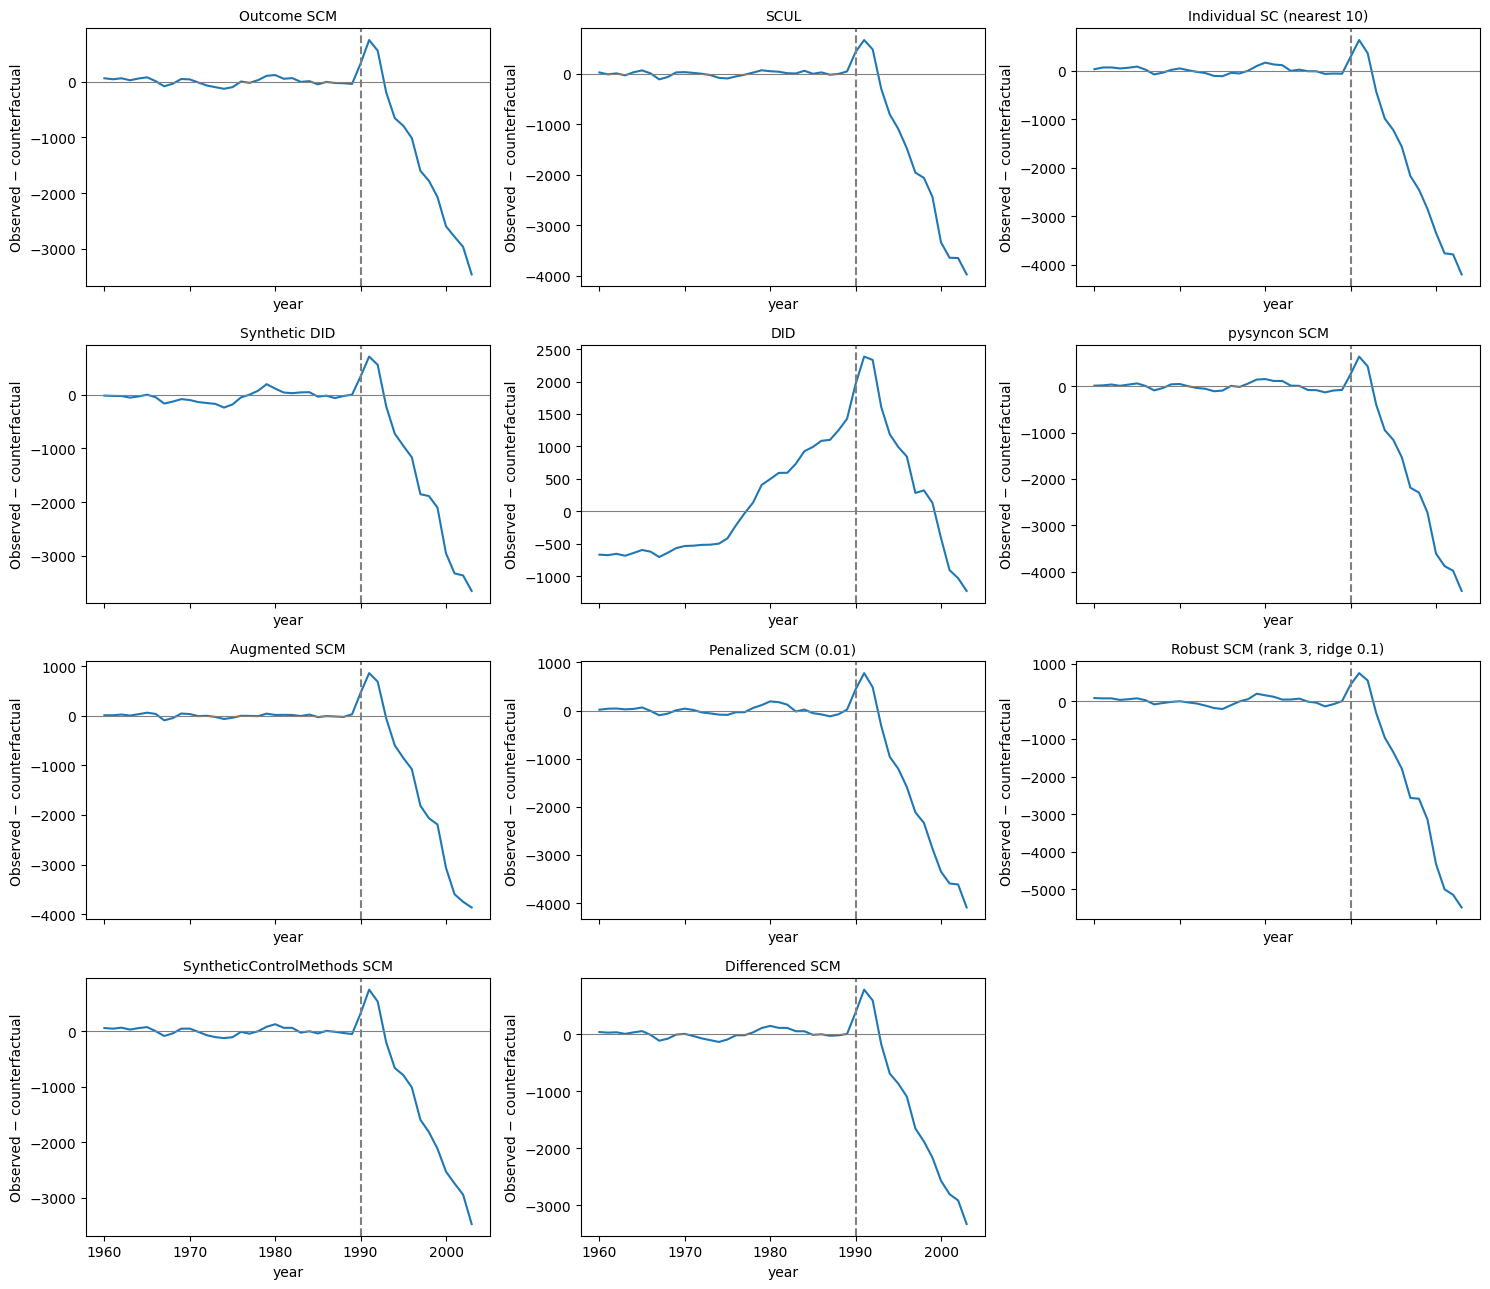

In [5]:
fig, axes = plt.subplots(4, 3, figsize=(15, 13), sharex=True)
for ax, (label, result) in zip(axes.flat, results.items()):
    result.plot(ax=ax, effects=True)
    ax.set_title(label, fontsize=10)
    ax.get_legend().remove()
axes.flat[-1].set_visible(False)
fig.tight_layout()
plt.show()

In [6]:
weights = pd.concat({label: fit.weights for label, fit in results.items()}, axis=1)
weights.loc[weights.abs().max(axis=1).sort_values(ascending=False).index].head(15).round(4)

,Outcome SCM,SCUL,Individual SC (nearest 10),Synthetic DID,DID,pysyncon SCM,Augmented SCM,Penalized SCM (0.01),"Robust SCM (rank 3, ridge 0.1)",SyntheticControlMethods SCM,Differenced SCM
Austria,0.3168,0.2474,0.3259,0.1070,0.0625,0.3214,0.1563,0.4234,0.0651,0.3462,0.2740
USA,0.3421,0.2174,0.3368,0.1645,0.0625,0.2994,0.2162,0.3069,0.0895,0.3705,0.3295
Italy,0.0537,0.3678,0.0000,0.0725,0.0625,0.0163,0.1752,0.0000,0.0525,0.0000,0.1371
Spain,0.0000,0.0000,0.0000,0.0000,0.0625,0.0000,-0.1920,0.0000,0.0735,0.0000,0.0000
France,0.0590,0.0000,0.1157,0.0767,0.0625,0.0000,0.1725,0.0000,0.0659,0.1058,0.0000
Denmark,0.0000,0.0000,0.0456,0.0649,0.0625,0.0134,0.0294,0.1676,0.0832,0.0000,0.0857
Switzerland,0.1053,0.0000,0.0000,0.1536,0.0625,0.0920,0.0789,0.0000,0.0406,0.0790,0.0752
Netherlands,0.0000,0.0000,0.1534,0.0699,0.0625,0.0769,0.1062,0.0366,0.0847,0.0000,0.0362
Norway,0.0274,0.1058,0.0000,0.0958,0.0625,0.0898,0.0733,0.0000,0.1478,0.0000,0.0000
UK,0.0000,0.0000,0.0000,0.0066,0.0625,0.0586,0.1384,0.0000,0.0889,0.0000,0.0000


## Interpretation and reproducibility

The ATT is the average observed-minus-counterfactual gap in the post-period, in the stated outcome units. Negative effects mean an outcome below its estimated untreated path. No automatic confidence interval is reported: serial dependence, donor eligibility, spillovers and assignment assumptions need a defensible inferential design.

`pysynth.placebo_test` offers in-space RMSPE-ratio diagnostics and a rank p-value under exchangeability assumptions. It is not the synthdid package's placebo variance estimator. SCUL's original scanner-data empirical study and the costofcare/ISC survey study are not reproduced here: their original data and full research designs differ from these public canonical panels.

The downloaded bytes and software versions are recorded above. Re-run the notebook from a fresh kernel to reproduce both the reference check and the comparison.